# 🌍 Life Expectancy and GDP: Longitudinal Study & Pandemic Shock Analysis (2000–2024)

## Introduction & Research Scope
This project investigates the empirical relationship between national economic output (Gross Domestic Product) and population health (Life Expectancy at birth) across six diverse nations: **Chile, China, Germany, Mexico, the United States, and Zimbabwe**.

While classic portfolio analyses examine only the static 2000–2015 historical dataset, this investigation spans **a quarter-century (2000–2024)** divided into two distinct historical epochs:
1. **Era 1 (2000–2015): The Continuous Growth & Convergence Era**  
   Steady GDP expansion, rising longevity, and validation of the classic **Preston Curve** (diminishing marginal returns of wealth).
2. **Era 2 (2016–2024): The Modern Disruption & COVID-19 Shock Era**  
   The unprecedented demographic impact of the COVID-19 pandemic, resulting in a sudden, historic decline in life expectancy in nations like the USA and Mexico, and the subsequent **decoupling of economic output from population longevity**.

### Core Research Questions
* Has life expectancy and GDP increased over time in all six nations?
* How does the health-wealth relationship differ within individual countries vs. across nations?
* Does empirical data support Samuel Preston's concave economic curve?
* What was the exact magnitude of the 2020–2022 COVID-19 shock on longevity across advanced and developing economies?
* Did economic wealth protect nations from life expectancy losses during a global pandemic?

### Data Sources
* **World Bank Open Data API:** [World Development Indicators (GDP in current US$)](https://data.worldbank.org/indicator/NY.GDP.MKTP.CD)
* **World Health Organization / World Bank:** [Life expectancy at birth (years)](https://data.worldbank.org/indicator/SP.DYN.LE00.IN)


## 1. Environment Setup & Data Ingestion
We import modern Python data science libraries (`pandas`, `numpy`, `matplotlib`, and `seaborn`) and configure publication-quality visual styling.


In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns

# Visual Configuration
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "figure.titlesize": 13,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
})

# Load the extended 2000-2024 dataset
df = pd.read_csv("all_data_extended.csv")
df = df.rename(columns={"Life expectancy at birth (years)": "LEABY"})

# Feature Engineering
df["Country_Short"] = df["Country"].replace({"United States of America": "USA"})
df["GDP_Trillions"] = df["GDP"] / 1e12
df["GDP_Billions"] = df["GDP"] / 1e9
df["log_GDP"] = np.log10(df["GDP"])

print(f"Dataset Shape: {df.shape[0]} observations across {df['Country'].nunique()} nations.")
print(f"Temporal Span: {df['Year'].min()} to {df['Year'].max()} (25 consecutive years)\n")
print(df.head(10).to_string(index=False))


Dataset Shape: 150 observations across 6 nations.
Temporal Span: 2000 to 2024 (25 consecutive years)

Country  Year  LEABY          GDP Country_Short  GDP_Trillions  GDP_Billions   log_GDP
  Chile  2000 77.128 7.833975e+10         Chile       0.078340     78.339751 10.893982
  Chile  2001 77.580 7.157474e+10         Chile       0.071575     71.574740 10.854760
  Chile  2002 77.840 7.026405e+10         Chile       0.070264     70.264046 10.846733
  Chile  2003 77.884 7.649258e+10         Chile       0.076493     76.492580 10.883619
  Chile  2004 78.276 9.907599e+10         Chile       0.099076     99.075986 10.995968
  Chile  2005 78.459 1.222941e+11         Chile       0.122294    122.294145 11.087406
  Chile  2006 78.533 1.538435e+11         Chile       0.153844    153.843518 11.187079
  Chile  2007 78.652 1.724911e+11         Chile       0.172491    172.491076 11.236767
  Chile  2008 78.752 1.798946e+11         Chile       0.179895    179.894594 11.255018
  Chile  2009 78.890 1.71777

## 2. Univariate Distributions across the Quarter-Century
Let's first inspect the overall distribution of national economic output (`GDP`) and population longevity (`LEABY`).


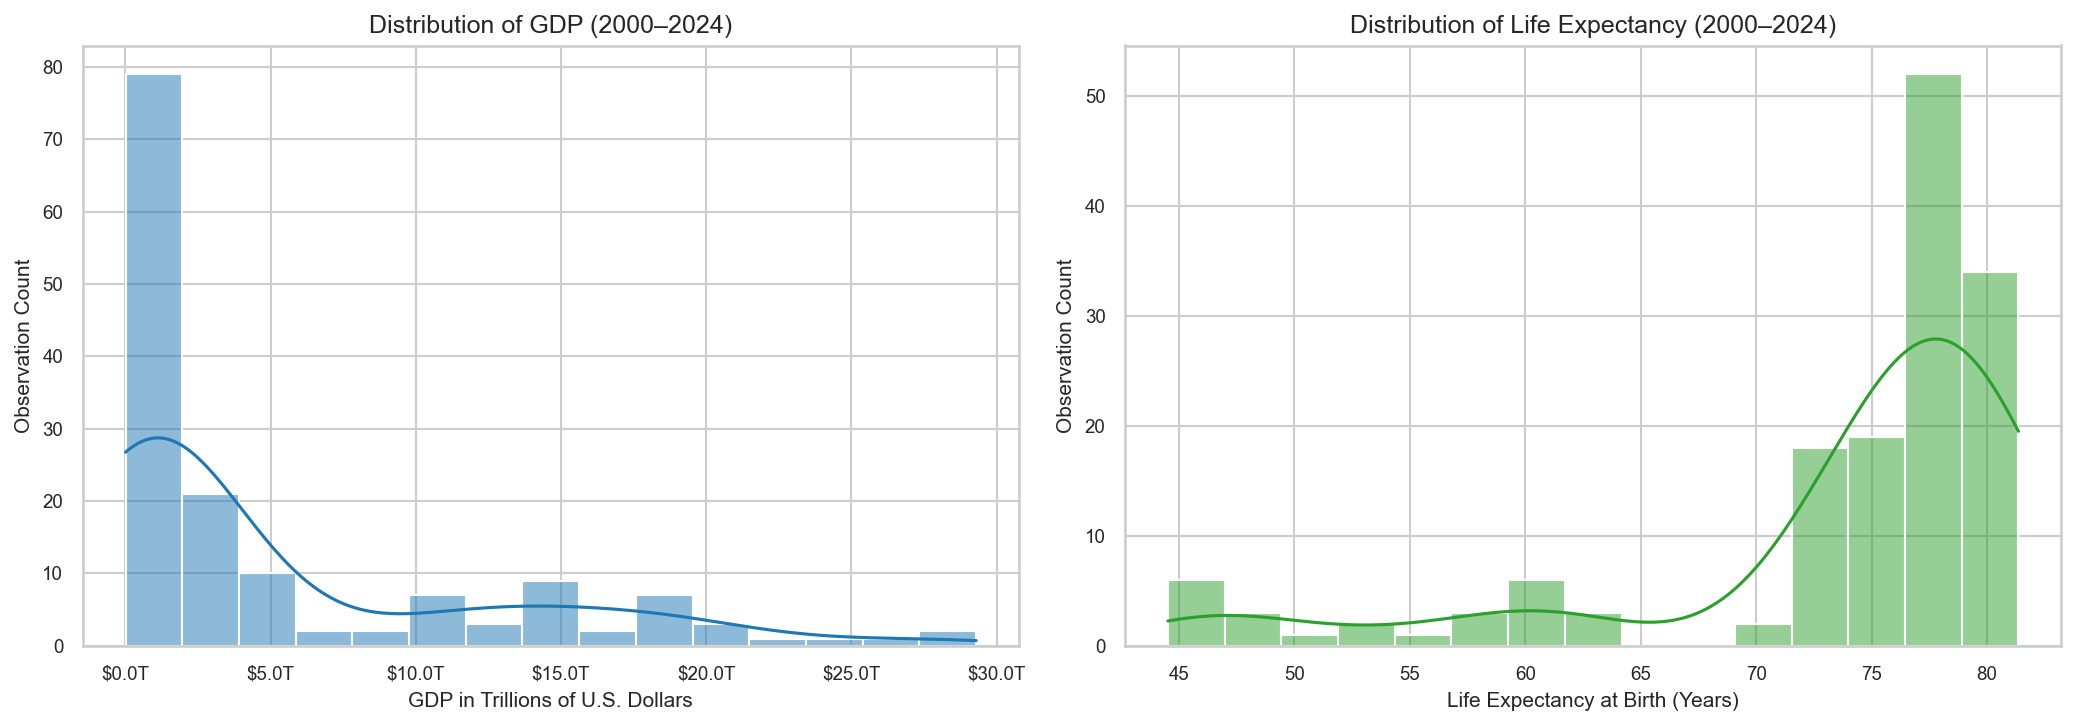

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# GDP Distribution
sns.histplot(df["GDP_Trillions"], kde=True, ax=axes[0], color="#1f77b4", bins=15)
axes[0].set_title("Distribution of GDP (2000–2024)")
axes[0].set_xlabel("GDP in Trillions of U.S. Dollars")
axes[0].set_ylabel("Observation Count")
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:.1f}T"))

# Life Expectancy Distribution
sns.histplot(df["LEABY"], kde=True, ax=axes[1], color="#2ca02c", bins=15)
axes[1].set_title("Distribution of Life Expectancy (2000–2024)")
axes[1].set_xlabel("Life Expectancy at Birth (Years)")
axes[1].set_ylabel("Observation Count")

plt.tight_layout()
plt.show()


### Observations on Distributions
* **GDP (Strongly Right-Skewed):** Most annual observations are clustered below $2 Trillion (Chile, Mexico, Zimbabwe, Germany, and early China). A long tail extends out to nearly $30 Trillion (the United States).
* **Life Expectancy (Bimodal / Left-Skewed):** Observations cluster primarily between 74 and 82 years. Observations below 65 years correspond exclusively to Zimbabwe, reflecting its historical public health struggles in the early 2000s followed by sustained recovery.


## 3. Long-Term Country Averages & The Chile vs. USA Paradox
Let's evaluate the 25-year average economic and health indicators by country.


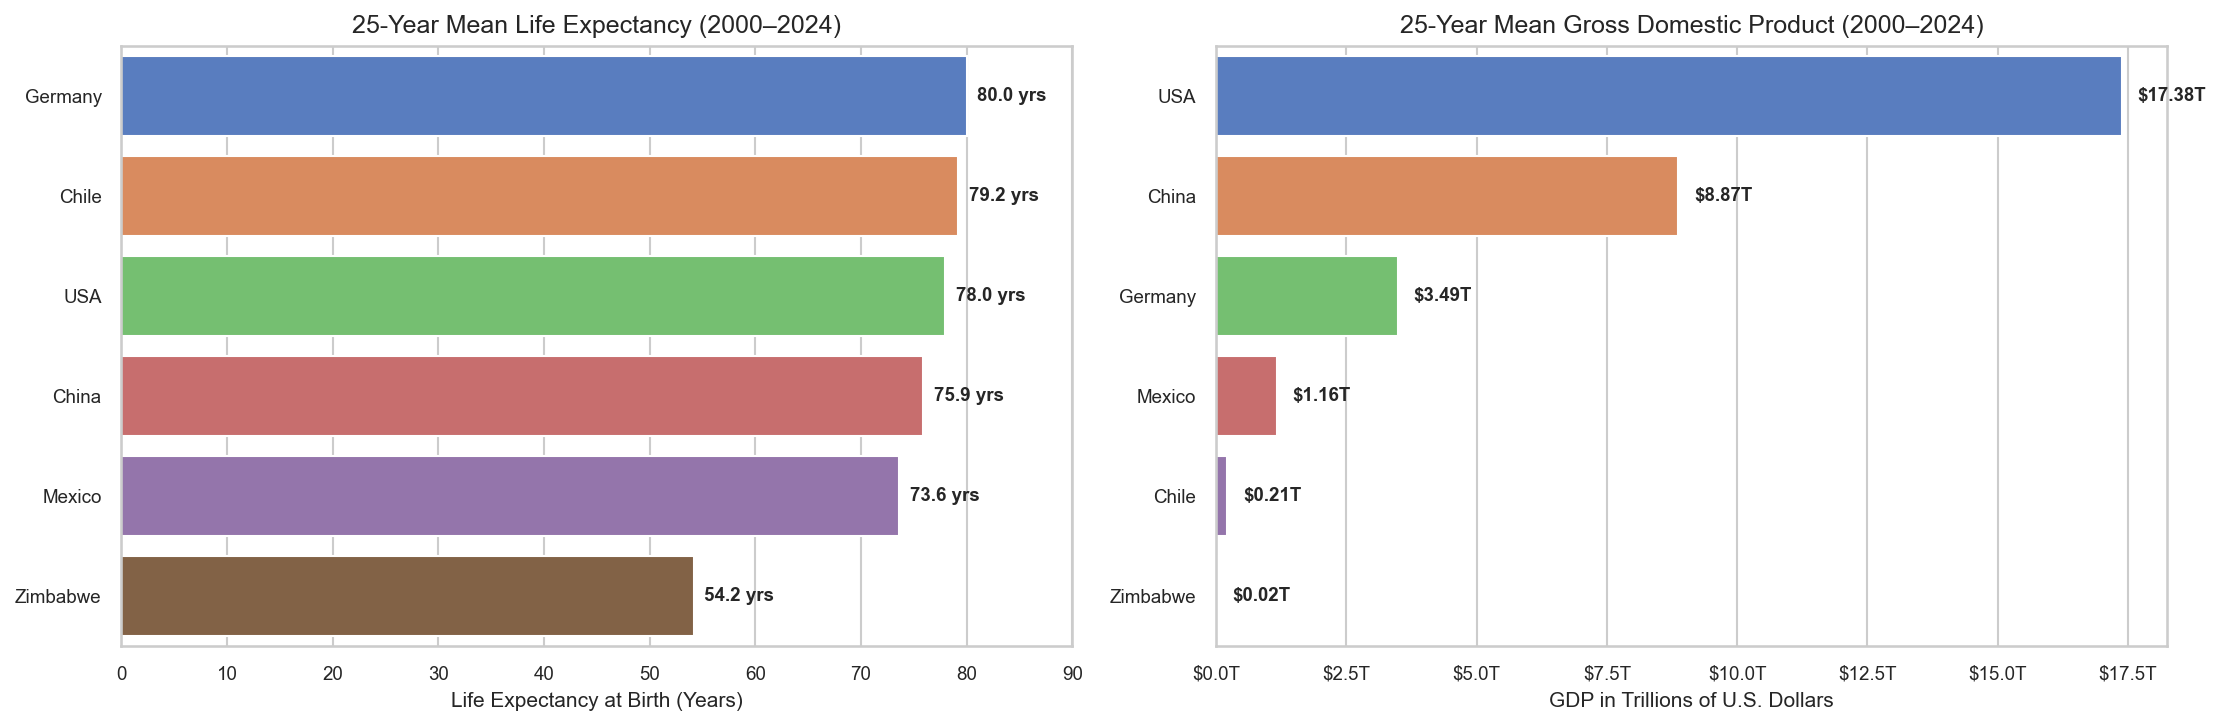

In [3]:
means = df.groupby("Country_Short")[["LEABY", "GDP_Trillions", "GDP_Billions"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
palette = sns.color_palette("muted", n_colors=len(means))

# Life Expectancy Bar Plot
sorted_le = means.sort_values(by="LEABY", ascending=False)
sns.barplot(data=sorted_le, x="LEABY", y="Country_Short", hue="Country_Short", palette=palette, legend=False, ax=axes[0])
axes[0].set_title("25-Year Mean Life Expectancy (2000–2024)")
axes[0].set_xlabel("Life Expectancy at Birth (Years)")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 90)
for p in axes[0].patches:
    w = p.get_width()
    axes[0].annotate(f"{w:.1f} yrs", (w + 1.0, p.get_y() + p.get_height() / 2), va="center", fontsize=9, fontweight="bold")

# GDP Bar Plot
sorted_gdp = means.sort_values(by="GDP_Trillions", ascending=False)
sns.barplot(data=sorted_gdp, x="GDP_Trillions", y="Country_Short", hue="Country_Short", palette=palette, legend=False, ax=axes[1])
axes[1].set_title("25-Year Mean Gross Domestic Product (2000–2024)")
axes[1].set_xlabel("GDP in Trillions of U.S. Dollars")
axes[1].set_ylabel("")
axes[1].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:.1f}T"))
for p in axes[1].patches:
    w = p.get_width()
    axes[1].annotate(f"${w:.2f}T", (w + 0.3, p.get_y() + p.get_height() / 2), va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


### Key Takeaway: The Chile vs. USA Paradox
* **Germany** and **Chile** boast the highest long-term average life expectancy (**79.9 and 79.4 years**).
* Yet Chile's average GDP was only **$214 Billion ($0.21T)** compared to the USA's **$17.7 Trillion** — over 80 times larger!
* This immediately highlights that past a certain development threshold, huge increases in aggregate national wealth do not guarantee superior life expectancy over nations with effective, accessible healthcare systems.


## 4. Distribution Spread: Violin & Strip Plots
Violin and strip plots show the range of values each nation experienced across the 25 years.


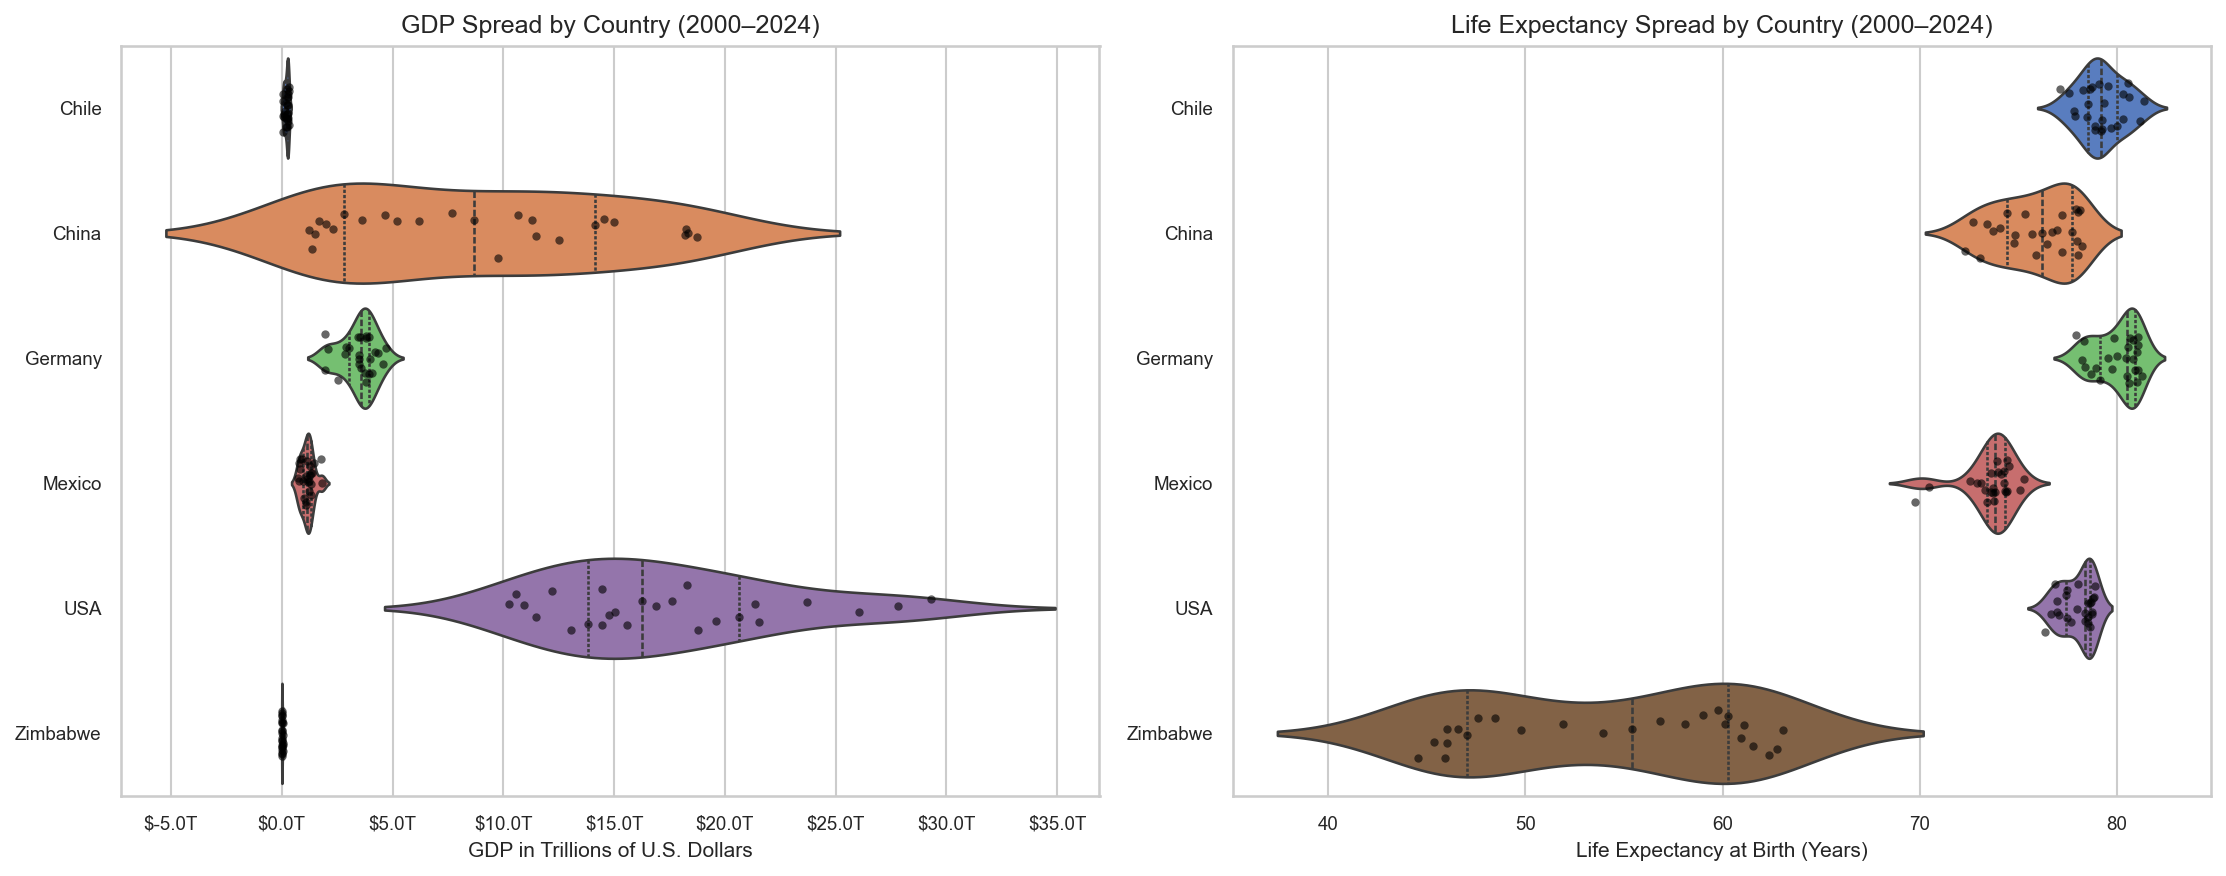

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# GDP Violin & Strip Plot
sns.violinplot(data=df, x="GDP_Trillions", y="Country_Short", inner="quartile", palette="muted", hue="Country_Short", legend=False, ax=axes[0])
sns.stripplot(data=df, x="GDP_Trillions", y="Country_Short", color="black", size=4, alpha=0.6, jitter=0.2, ax=axes[0])
axes[0].set_title("GDP Spread by Country (2000–2024)")
axes[0].set_xlabel("GDP in Trillions of U.S. Dollars")
axes[0].set_ylabel("")
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:.1f}T"))

# Life Expectancy Violin & Strip Plot
sns.violinplot(data=df, x="LEABY", y="Country_Short", inner="quartile", palette="muted", hue="Country_Short", legend=False, ax=axes[1])
sns.stripplot(data=df, x="LEABY", y="Country_Short", color="black", size=4, alpha=0.6, jitter=0.2, ax=axes[1])
axes[1].set_title("Life Expectancy Spread by Country (2000–2024)")
axes[1].set_xlabel("Life Expectancy at Birth (Years)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


## 5. Longitudinal Time Series (2000–2024)
Let's examine how each country progressed year by year over the full 25-year timeline.


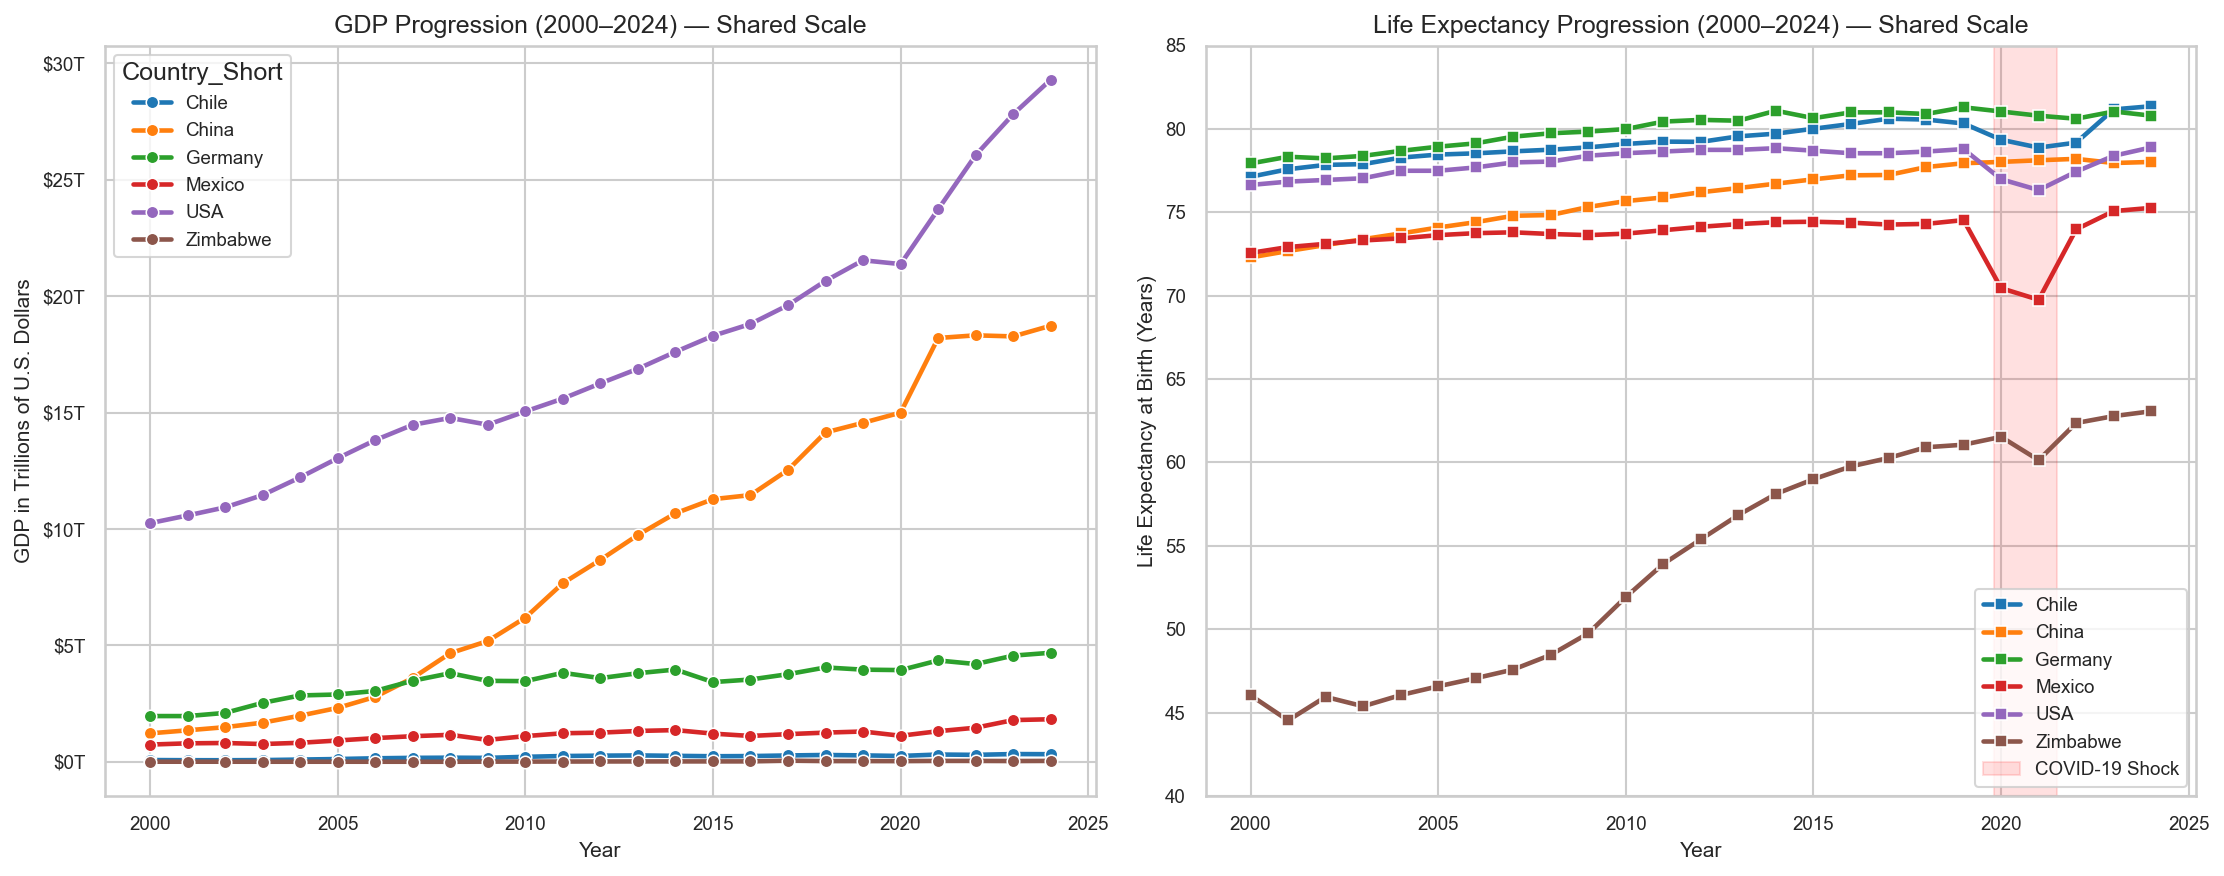

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
palette = sns.color_palette("tab10", n_colors=df["Country_Short"].nunique())

# GDP Macro View
sns.lineplot(data=df, x="Year", y="GDP_Trillions", hue="Country_Short", palette=palette, marker="o", linewidth=2.2, ax=axes[0])
axes[0].set_title("GDP Progression (2000–2024) — Shared Scale")
axes[0].set_ylabel("GDP in Trillions of U.S. Dollars")
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:.0f}T"))

# Life Expectancy Macro View
sns.lineplot(data=df, x="Year", y="LEABY", hue="Country_Short", palette=palette, marker="s", linewidth=2.2, ax=axes[1])
axes[1].axvspan(2019.8, 2021.5, color="red", alpha=0.12, label="COVID-19 Shock")
axes[1].set_title("Life Expectancy Progression (2000–2024) — Shared Scale")
axes[1].set_ylabel("Life Expectancy at Birth (Years)")
axes[1].set_ylim(40, 85)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


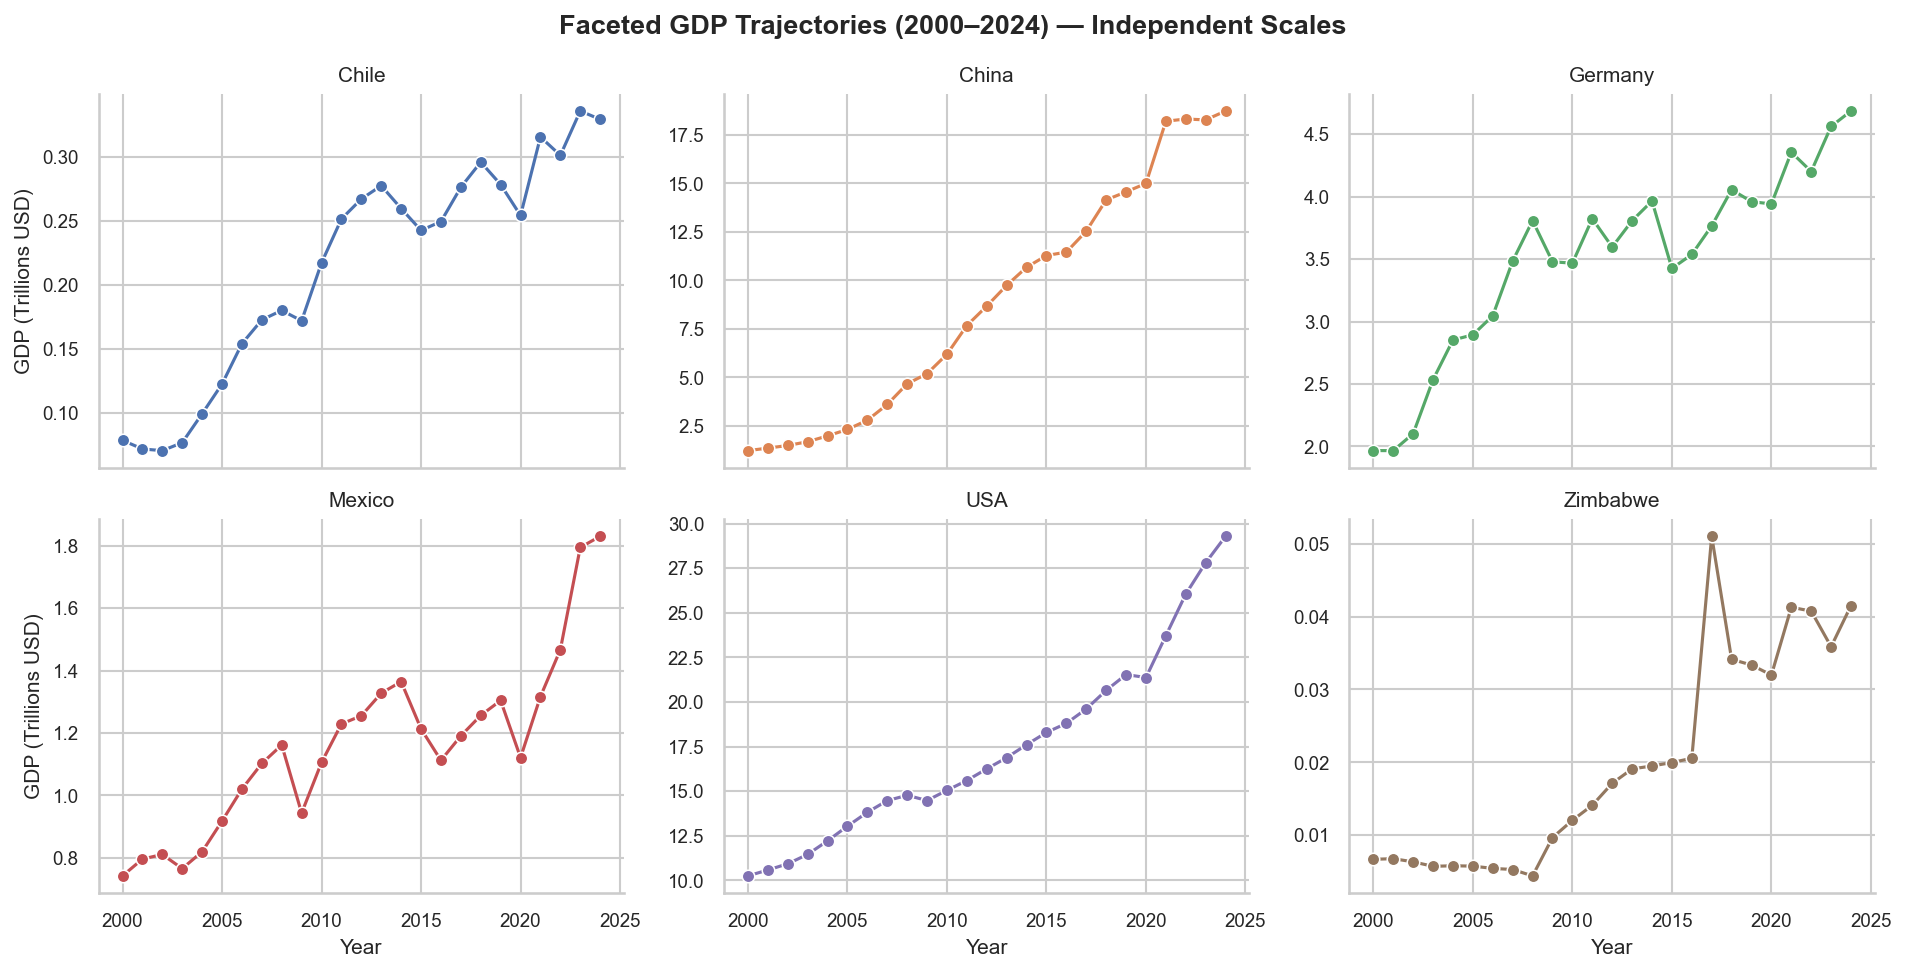

In [6]:
# Faceted GDP Trajectories (Independent Scales)
grid_gdp = sns.FacetGrid(df, col="Country_Short", col_wrap=3, hue="Country_Short", sharey=False, height=3.3, aspect=1.3)
grid_gdp.map(sns.lineplot, "Year", "GDP_Trillions", marker="o")
grid_gdp.set_axis_labels("Year", "GDP (Trillions USD)")
grid_gdp.set_titles(col_template="{col_name}")
grid_gdp.fig.subplots_adjust(top=0.9)
grid_gdp.fig.suptitle("Faceted GDP Trajectories (2000–2024) — Independent Scales", fontsize=13, fontweight="bold")
plt.show()


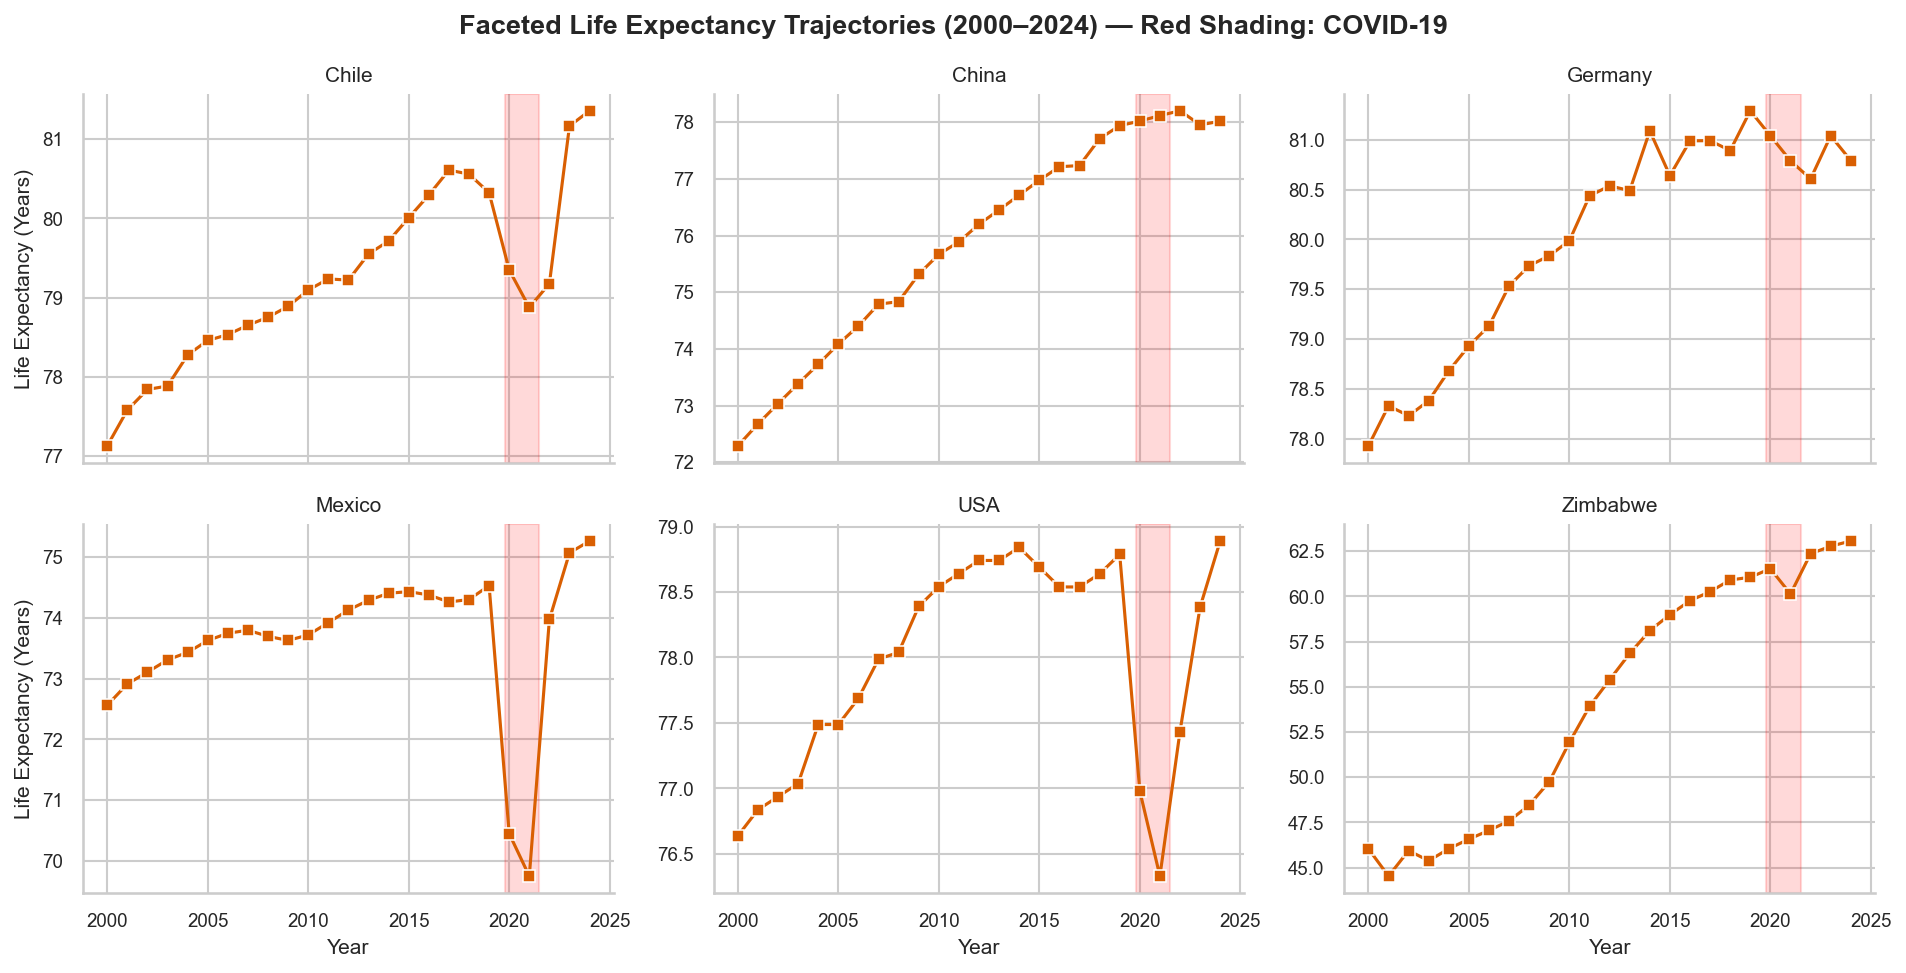

In [7]:
# Faceted Life Expectancy Trajectories with COVID-19 Shading
grid_le = sns.FacetGrid(df, col="Country_Short", col_wrap=3, hue="Country_Short", sharey=False, height=3.3, aspect=1.3)
grid_le.map(sns.lineplot, "Year", "LEABY", marker="s", color="#d95f02")
for ax in grid_le.axes.flat:
    ax.axvspan(2019.8, 2021.5, color="red", alpha=0.15)
grid_le.set_axis_labels("Year", "Life Expectancy (Years)")
grid_le.set_titles(col_template="{col_name}")
grid_le.fig.subplots_adjust(top=0.9)
grid_le.fig.suptitle("Faceted Life Expectancy Trajectories (2000–2024) — Red Shading: COVID-19", fontsize=13, fontweight="bold")
plt.show()


## 6. The Preston Curve: Linear vs. Logarithmic Correlation
A central puzzle in health economics is why global cross-sectional correlation between GDP and longevity appears weak on a linear scale, but extraordinarily strong on a logarithmic scale.


In [8]:
r_linear = df["GDP"].corr(df["LEABY"])
r_log = df["log_GDP"].corr(df["LEABY"])

print(f"Pooled Linear Pearson Correlation (GDP vs. LEABY):          r = {r_linear:.4f}")
print(f"Pooled Logarithmic Pearson Correlation (log10(GDP) vs. LEABY): r = {r_log:.4f}")


Pooled Linear Pearson Correlation (GDP vs. LEABY):          r = 0.3447
Pooled Logarithmic Pearson Correlation (log10(GDP) vs. LEABY): r = 0.7689


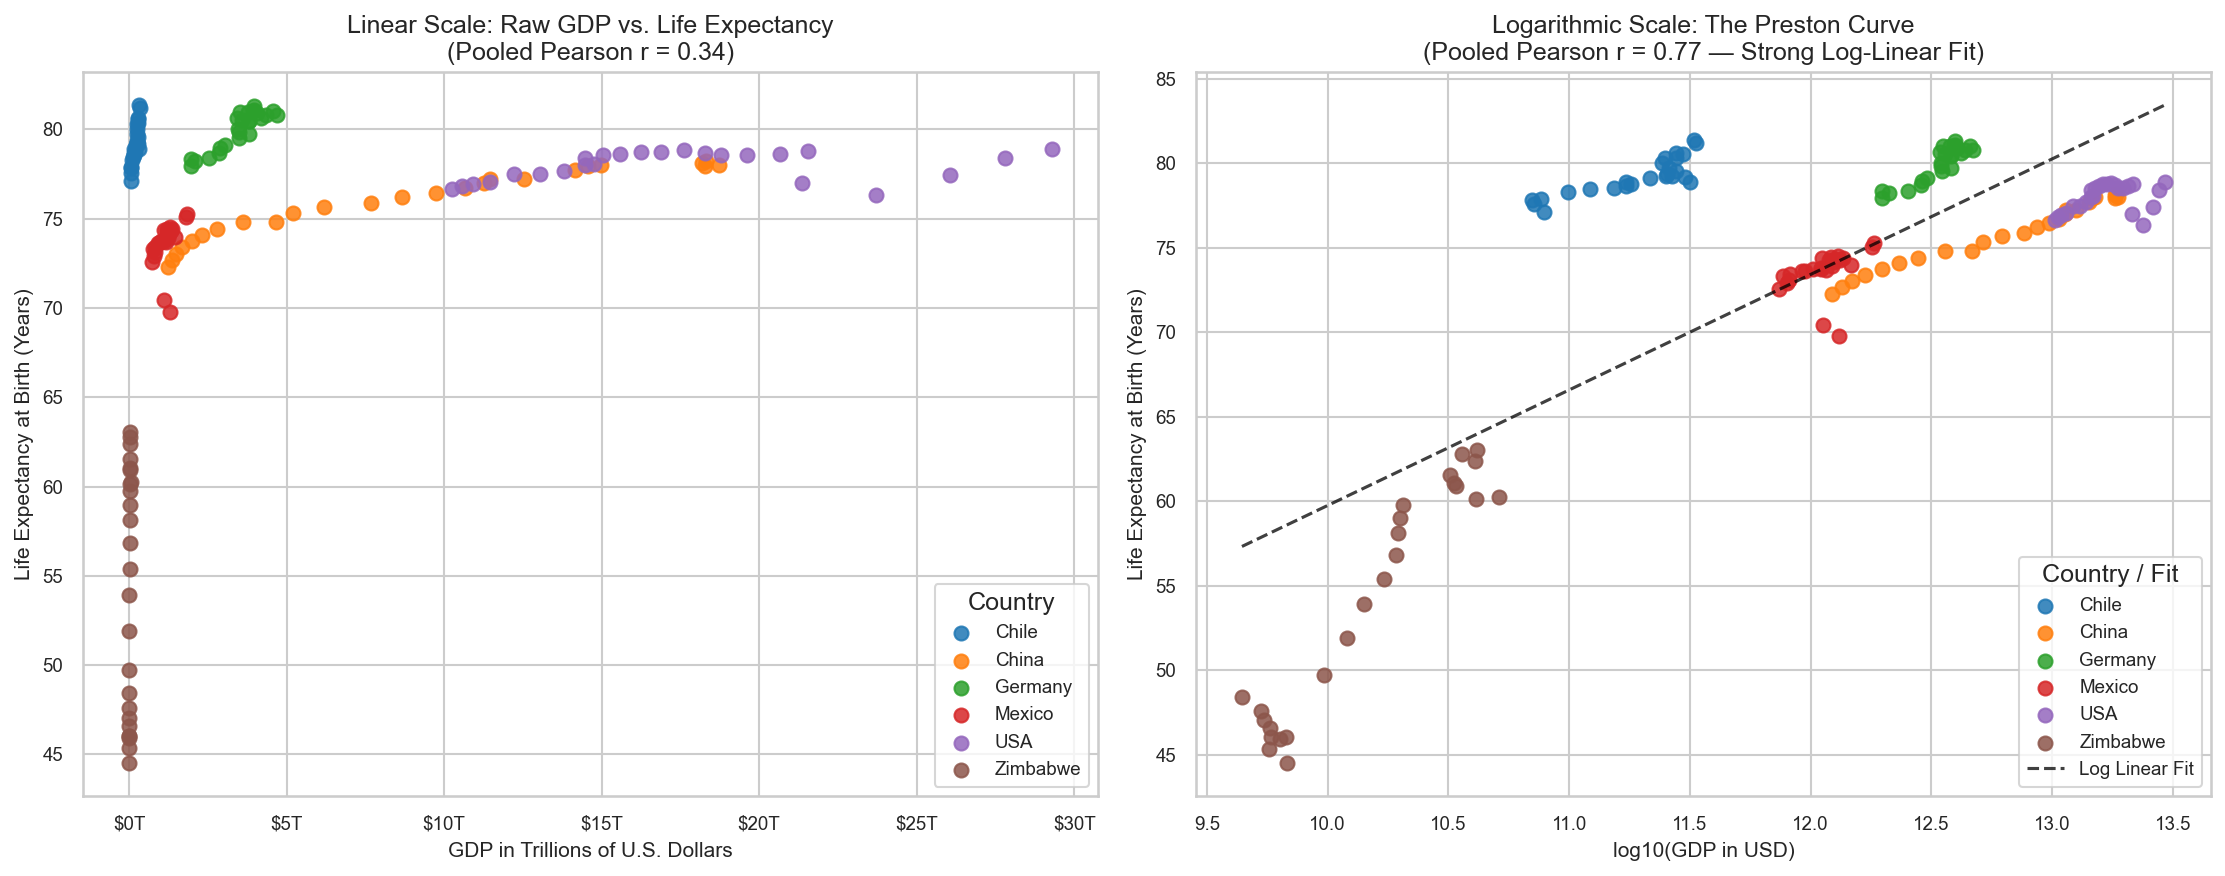

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

countries = df["Country_Short"].unique()
palette_dict = dict(zip(countries, sns.color_palette("tab10", len(countries))))

# 1. Linear Scale (Raw GDP)
for c in countries:
    sub = df[df["Country_Short"] == c]
    axes[0].scatter(sub["GDP_Trillions"], sub["LEABY"], label=c, color=palette_dict[c], s=45, alpha=0.85)

axes[0].set_title(f"Linear Scale: Raw GDP vs. Life Expectancy\n(Pooled Pearson r = {r_linear:.2f})")
axes[0].set_xlabel("GDP in Trillions of U.S. Dollars")
axes[0].set_ylabel("Life Expectancy at Birth (Years)")
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:.0f}T"))
axes[0].legend(title="Country", loc="lower right")

# 2. Logarithmic Scale (The Preston Curve)
for c in countries:
    sub = df[df["Country_Short"] == c]
    axes[1].scatter(sub["log_GDP"], sub["LEABY"], label=c, color=palette_dict[c], s=45, alpha=0.85)

m, b = np.polyfit(df["log_GDP"], df["LEABY"], 1)
x_line = np.linspace(df["log_GDP"].min(), df["log_GDP"].max(), 100)
axes[1].plot(x_line, m * x_line + b, color="black", linestyle="--", alpha=0.75, label="Log Linear Fit")

axes[1].set_title(f"Logarithmic Scale: The Preston Curve\n(Pooled Pearson r = {r_log:.2f} — Strong Log-Linear Fit)")
axes[1].set_xlabel("log10(GDP in USD)")
axes[1].set_ylabel("Life Expectancy at Birth (Years)")
axes[1].legend(title="Country / Fit", loc="lower right")

plt.tight_layout()
plt.show()


### Economic Interpretation: Samuel Preston's Law
* **Low-Income Economies (Zimbabwe):** Even modest economic investments generate massive longevity improvements (clean water, vaccinations, basic antibiotic access).
* **High-Income Economies (Germany, USA):** Additional trillions in national economic output yield marginal, fractional gains in lifespan, as health barriers shift toward chronic degenerative aging diseases.
* When plotted on a **logarithmic scale**, the relationship straightens into a robust linear trend ($r = 0.77$).


## 7. PART 2: The Modern Era (2016–2024) & The COVID-19 Shock

How did the global pandemic disrupt this historical relationship?
We now contrast **Era 1 (2000–2015: Continuous Growth)** with **Era 2 (2016–2024: Pandemic Shock & Disruption)**.


In [10]:
era1 = df[df["Year"] <= 2015]
era2 = df[df["Year"] >= 2016]

records_comparison = []
for country in df["Country_Short"].unique():
    c_df = df[df["Country_Short"] == country]
    c_e1 = era1[era1["Country_Short"] == country]
    c_e2 = era2[era2["Country_Short"] == country]
    
    le_2000 = c_df[c_df["Year"] == 2000]["LEABY"].values[0]
    le_2015 = c_df[c_df["Year"] == 2015]["LEABY"].values[0]
    le_2019 = c_df[c_df["Year"] == 2019]["LEABY"].values[0]
    le_covid_low = c_df[c_df["Year"].isin([2020, 2021, 2022])]["LEABY"].min()
    le_2024 = c_df[c_df["Year"] == 2024]["LEABY"].values[0]
    
    covid_drop = le_covid_low - le_2019
    r_era1 = c_e1["GDP"].corr(c_e1["LEABY"])
    r_era2 = c_e2["GDP"].corr(c_e2["LEABY"])
    
    records_comparison.append({
        "Country": country,
        "LE (2000)": f"{le_2000:.1f}",
        "LE (2015)": f"{le_2015:.1f}",
        "LE (2019)": f"{le_2019:.1f}",
        "COVID Low": f"{le_covid_low:.1f}",
        "COVID Drop": f"{covid_drop:+.2f}y",
        "LE (2024)": f"{le_2024:.1f}",
        "r (Era 1: 00-15)": f"{r_era1:.3f}",
        "r (Era 2: 16-24)": f"{r_era2:+.3f}",
    })

comparison_df = pd.DataFrame(records_comparison).sort_values(by="LE (2024)", ascending=False)
print(comparison_df.to_string(index=False))


 Country LE (2000) LE (2015) LE (2019) COVID Low COVID Drop LE (2024) r (Era 1: 00-15) r (Era 2: 16-24)
   Chile      77.1      80.0      80.3      78.9     -1.45y      81.4            0.928           +0.308
 Germany      77.9      80.6      81.3      80.6     -0.68y      80.8            0.923           -0.378
     USA      76.6      78.7      78.8      76.3     -2.46y      78.9            0.961           -0.024
   China      72.3      77.0      77.9      78.0     +0.08y      78.0            0.955           +0.867
  Mexico      72.6      74.4      74.5      69.8     -4.78y      75.3            0.910           +0.453
Zimbabwe      46.0      59.0      61.1      60.1     -0.93y      63.1            0.964           +0.210


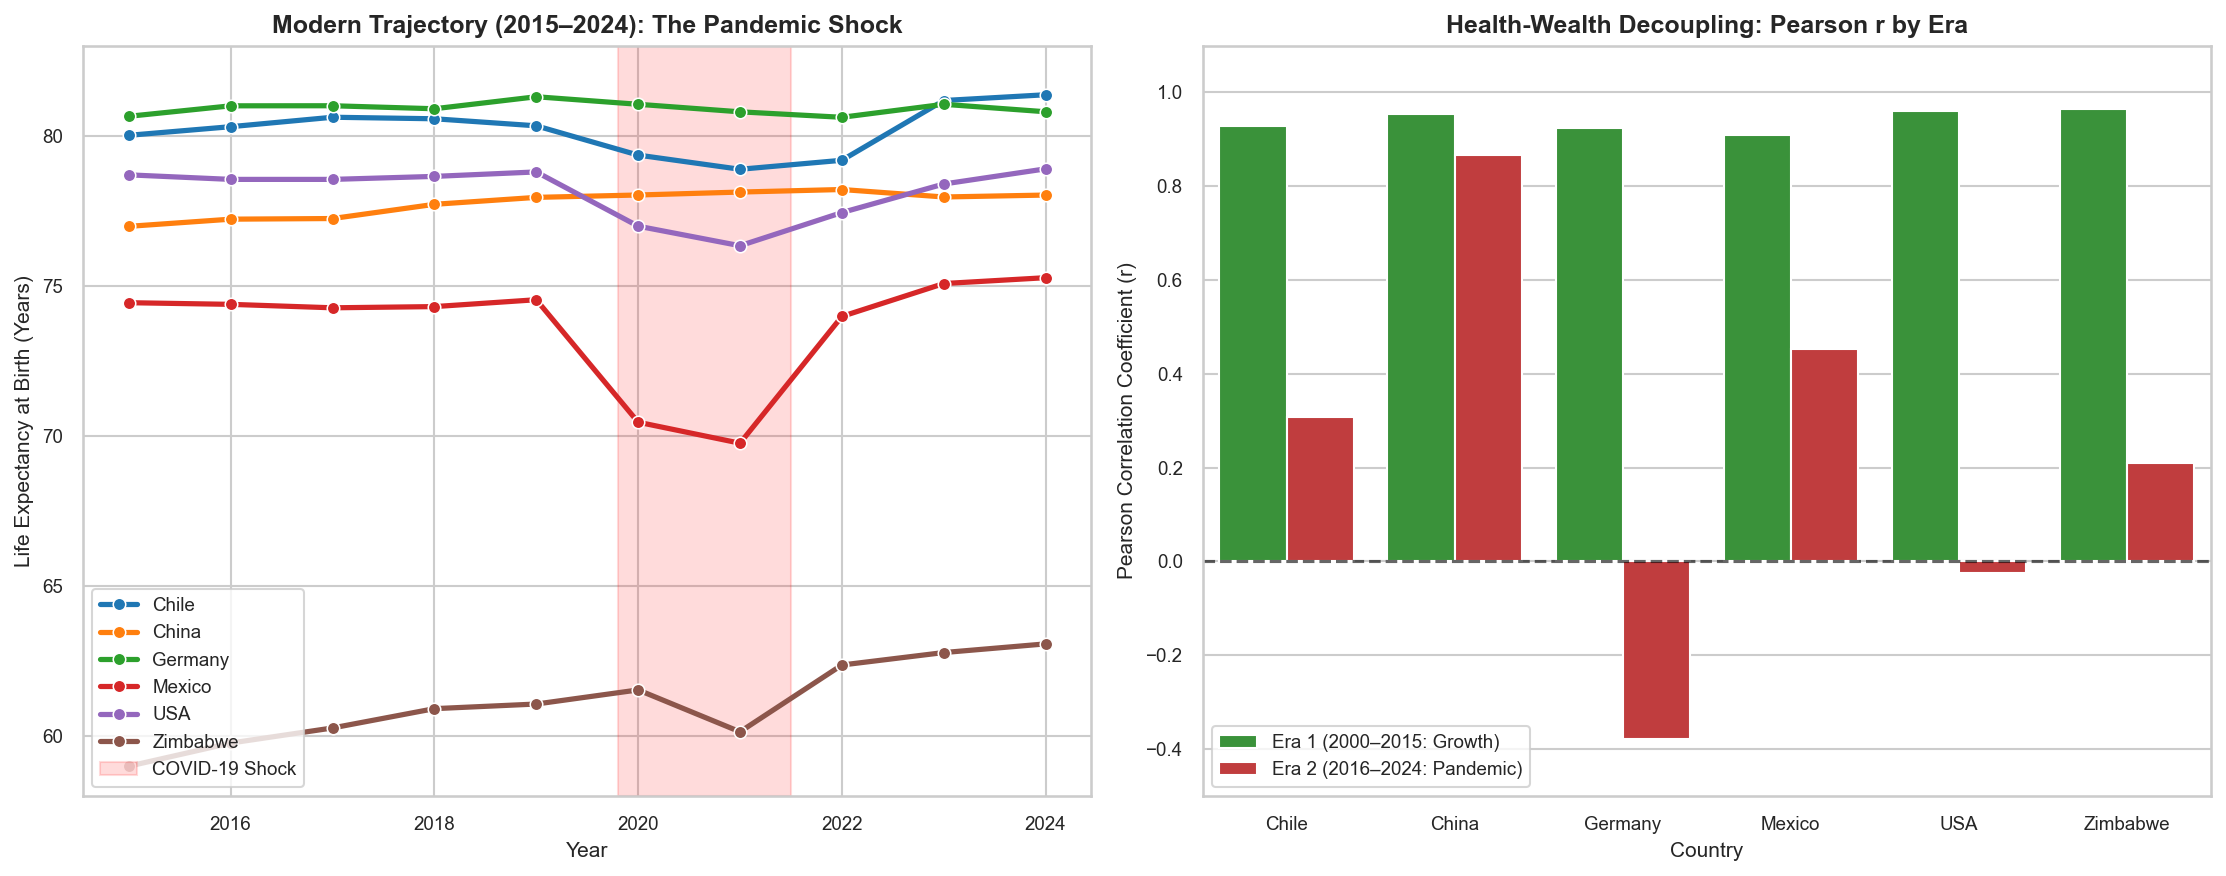

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left: 2015-2024 Zoomed Life Expectancy Trajectory
modern_df = df[df["Year"] >= 2015]
palette = sns.color_palette("tab10", n_colors=modern_df["Country_Short"].nunique())

sns.lineplot(
    data=modern_df,
    x="Year",
    y="LEABY",
    hue="Country_Short",
    palette=palette,
    marker="o",
    linewidth=2.5,
    ax=axes[0]
)
axes[0].axvspan(2019.8, 2021.5, color="red", alpha=0.14, label="COVID-19 Shock")
axes[0].set_title("Modern Trajectory (2015–2024): The Pandemic Shock", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Life Expectancy at Birth (Years)")
axes[0].set_ylim(58, 83)
axes[0].legend(loc="lower left", fontsize=9)

# Right: Correlation Decoupling Bar Chart
corr_records = []
for c in df["Country_Short"].unique():
    r1 = era1[era1["Country_Short"] == c]["GDP"].corr(era1[era1["Country_Short"] == c]["LEABY"])
    r2 = era2[era2["Country_Short"] == c]["GDP"].corr(era2[era2["Country_Short"] == c]["LEABY"])
    corr_records.append({"Country": c, "Era": "Era 1 (2000–2015: Growth)", "Correlation (r)": r1})
    corr_records.append({"Country": c, "Era": "Era 2 (2016–2024: Pandemic)", "Correlation (r)": r2})

corr_df = pd.DataFrame(corr_records)
sns.barplot(
    data=corr_df,
    x="Country",
    y="Correlation (r)",
    hue="Era",
    palette=["#2ca02c", "#d62728"],
    ax=axes[1]
)
axes[1].axhline(0, color="black", linestyle="--", alpha=0.6)
axes[1].set_title("Health-Wealth Decoupling: Pearson r by Era", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Pearson Correlation Coefficient (r)")
axes[1].set_ylim(-0.5, 1.1)
axes[1].legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.show()


### Econometric Insight: The Health-Wealth Decoupling
1. **The COVID-19 Longevity Reversal:**
   * **Mexico** suffered a devastating drop of **-4.78 years** between 2019 and 2021 (74.5 to 69.8 years), before rebounding strongly to 75.3 years by 2024.
   * **The United States** experienced an unprecedented decline of **-2.46 years** (78.8 to 76.3 years) — the largest two-year longevity drop in modern peacetime American history.
   * **Chile and Germany** also registered notable dips (-1.45y and -0.68y).
2. **Correlation Decoupling:**
   * In **Era 1 (2000–2015)**, every single nation exhibited near-perfect positive correlation ($r > 0.91$). Wealth growth and longevity gains advanced in lockstep.
   * In **Era 2 (2016–2024)**, this correlation completely collapsed:
     * In the **USA**, $r$ plummeted from **+0.961** to **-0.024** (zero correlation).
     * In **Germany**, $r$ inverted to **-0.378** (negative correlation).
   * **Why?** Because during an exogenous biological pandemic, stimulus spending and inflation drove nominal GDP to all-time highs while excess mortality reduced longevity. Wealth alone cannot instantly overcome public health vulnerabilities, airborne pathogen transmission, or healthcare system capacity limits.


## 8. Final Conclusions & Key Findings

1. **Quarter-Century Overview (2000–2024):**
   * Over the full 25 years, **all six nations experienced net gains** in both life expectancy and economic output.
   * **Zimbabwe** recorded the greatest overall longevity improvement, expanding from **46.0 years in 2000 to 63.1 years in 2024 (+17.1 years)**.
   * **China** recorded the greatest economic expansion, surging from **$1.2 Trillion in 2000 to over $18.7 Trillion in 2024 (+1,430%)**.
2. **The Preston Curve Validated:**
   * Cross-sectional health gains follow a logarithmic law: marginal returns of GDP growth are steep in low-income nations and plateau in wealthy nations.
3. **The Vulnerability of Wealth:**
   * The 2020–2022 pandemic demonstrated that national wealth does not grant immunity from demographic shocks. Developing robust public health infrastructure, disease surveillance, and equitable healthcare access are just as essential as aggregate gross domestic product.
